In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# ============================================================
# 1. Load data
# ============================================================

file_path = Path("data/eye_tracking_data.xlsx")
df = pd.read_excel(file_path)

DATASET_COL = "Dataset_Abbreviation"
RT_COL = "Duration_of_interval"

# Original response-time unit: milliseconds
RT_UNIT = "ms"

# The four datasets
datasets = ["STAT", "TMA", "SLSO", "STT"]


# ============================================================
# 2. Prepare data
# ============================================================

plot_df = df[[DATASET_COL, RT_COL]].copy()

# Remove leading and trailing spaces from dataset names
plot_df[DATASET_COL] = (
    plot_df[DATASET_COL]
    .astype("string")
    .str.strip()
)

# Combine STAT-A and STAT-B under STAT
plot_df[DATASET_COL] = plot_df[DATASET_COL].replace({
    "STAT-A": "STAT",
    "STAT-B": "STAT"
})

# Convert response times to numeric values
plot_df[RT_COL] = pd.to_numeric(
    plot_df[RT_COL],
    errors="coerce"
)

# Retain valid positive values from the four datasets
plot_df = plot_df[
    plot_df[DATASET_COL].isin(datasets)
    & plot_df[RT_COL].notna()
    & np.isfinite(plot_df[RT_COL])
    & (plot_df[RT_COL] > 0)
].copy()

# Convert to seconds
if RT_UNIT == "ms":
    plot_df["Response_Time_s"] = plot_df[RT_COL] / 1000
else:
    plot_df["Response_Time_s"] = plot_df[RT_COL]

In [3]:
# ============================================================
# 3. Calculate descriptive statistics
# ============================================================
summary = (
    plot_df.groupby(DATASET_COL)["Response_Time_s"]
    .agg(
        N="count",
        Mean="mean",
        SD="std",
        Median="median",
        Min="min",
        Max="max"
    )
    .reindex(datasets)
)

summary["Range"] = (
    summary["Min"].map(lambda x: f"{x:.2f}")
    + "–"
    + summary["Max"].map(lambda x: f"{x:.2f}")
)

print("Descriptive statistics of response time (s)")
display(
    summary[["N", "Mean", "SD", "Range", "Median"]].round(
        {"Mean": 2, "SD": 2, "Median": 2}
    )
)

Descriptive statistics of response time (s)


,N,Mean,SD,Range,Median
Dataset_Abbreviation,,,,,
STAT,5009,23.89,18.23,0.15–269.83,18.67
TMA,4804,19.18,14.37,0.04–151.59,14.58
SLSO,8367,24.53,17.54,0.01–184.75,19.73
STT,4589,19.94,20.16,0.34–131.12,11.22


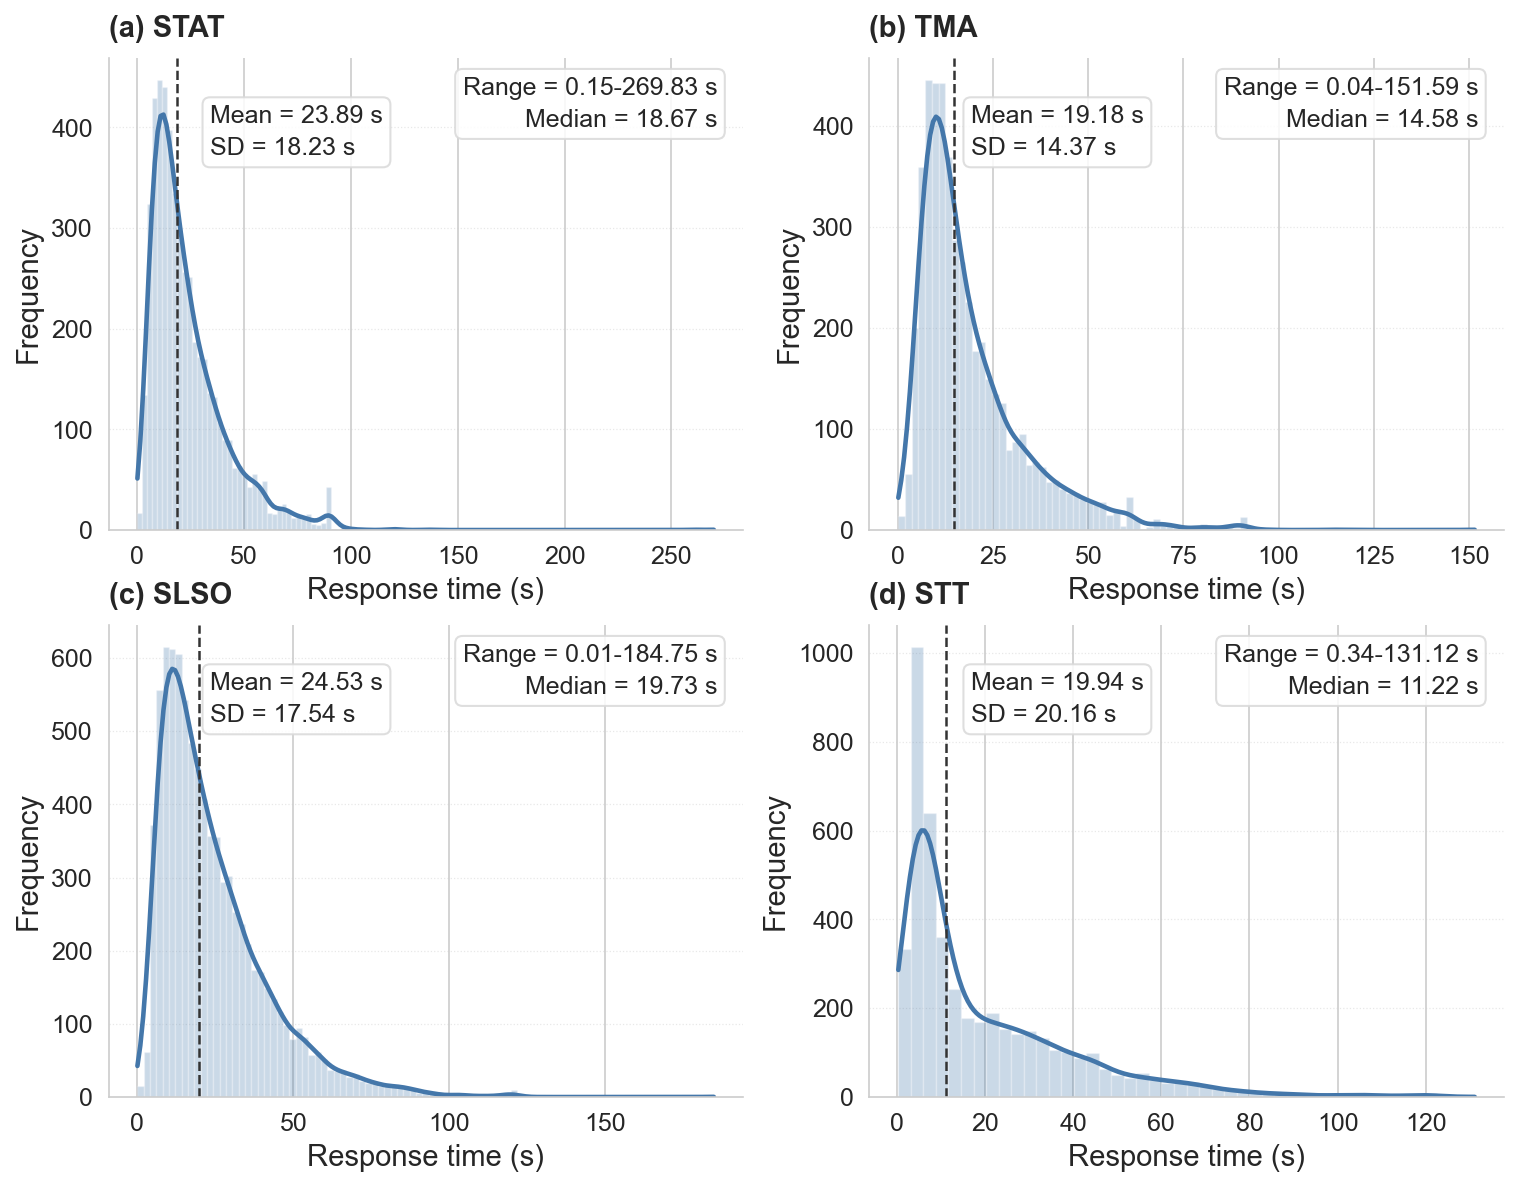

In [4]:
# ============================================================
# 4. Plot style
# ============================================================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

color = "#4477AA"

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

# ============================================================
# 5. Plot frequency histograms, KDE curves, and statistical annotations
# ============================================================
for i, dataset in enumerate(datasets):
    ax = axes[i]

    values = plot_df.loc[
        plot_df[DATASET_COL] == dataset,
        "Response_Time_s"
    ].dropna()

    ax.set_title(
        f"({chr(97 + i)}) {dataset}",
        loc="left",
        fontweight="bold",
        pad=10
    )

    if values.empty:
        ax.text(
            0.5, 0.5, "No valid data",
            ha="center", va="center",
            transform=ax.transAxes
        )
        ax.set_xlabel("Response time (s)")
        ax.set_ylabel("Frequency")
        continue

    # --------------------------------------------------------
    # Frequency histogram
    # --------------------------------------------------------
    counts, bin_edges, _ = ax.hist(
        values,
        bins="fd",
        color=color,
        alpha=0.28,
        edgecolor="white",
        linewidth=0.7
    )

    # --------------------------------------------------------
    # KDE curve: convert to the frequency scale
    # KDE on the frequency scale = density × sample size × bin width
    # --------------------------------------------------------
    if values.nunique() > 1 and len(bin_edges) > 1:
        sns.kdeplot(
            values,
            color=color,
            linewidth=2.2,
            cut=0,
            ax=ax
        )

        kde_line = ax.lines[-1]
        bin_width = np.mean(np.diff(bin_edges))

        kde_line.set_ydata(
            kde_line.get_ydata() * len(values) * bin_width
        )

    # --------------------------------------------------------
    # Median reference line
    # --------------------------------------------------------
    mean_rt = values.mean()
    sd_rt = values.std()
    median_rt = values.median()
    min_rt = values.min()
    max_rt = values.max()

    ax.axvline(
        median_rt,
        color="#333333",
        linestyle="--",
        linewidth=1.2
    )

    # --------------------------------------------------------
    # Mean and SD: upper left, avoiding the statistics in the upper right
    # Use axes-relative positions to prevent displacement when the x-axis range changes
    # --------------------------------------------------------
    ax.text(
        0.16, 0.90,
        f"Mean = {mean_rt:.2f} s\nSD = {sd_rt:.2f} s",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=12,
        linespacing=1.5,
        bbox=dict(
            facecolor="white",
            edgecolor="#D9D9D9",
            alpha=0.85,
            pad=3,
            boxstyle="round,pad=0.3"
        )
    )

    # --------------------------------------------------------
    # Range and Median: upper right
    # --------------------------------------------------------
    ax.text(
        0.96, 0.96,
        f"Range = {min_rt:.2f}-{max_rt:.2f} s\n"
        f"Median = {median_rt:.2f} s",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=12,
        linespacing=1.5,
        bbox=dict(
            facecolor="white",
            edgecolor="#D9D9D9",
            alpha=0.85,
            pad=3,
            boxstyle="round,pad=0.3"
        )
    )

    # --------------------------------------------------------
    # Axes and grid
    # --------------------------------------------------------
    ax.set_xlabel("Response time (s)")
    ax.set_ylabel("Frequency")

    ax.tick_params(
        axis="both",
        labelsize=12,
        direction="out",
        length=4,
        width=0.8
    )

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.6,
        alpha=0.45
    )
    ax.set_axisbelow(True)

In [5]:
# ============================================================
# 6. Adjust layout and save
# ============================================================
fig.tight_layout(pad=2.0)

output_png = "response_time_frequency_4_datasets.png"
fig.savefig(output_png, dpi=300)

plt.show()
